In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install streamlit pandas scikit-learn
!pip install folium streamlit-folium geopy
!pip install geopy xgboost
!wget -q -c https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb
!sudo sysctl -w net.core.rmem_max=3072000
!sudo sysctl -w net.core.wmem_max=3072000

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(Reading database ... 122817 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.10.7) over (2026.10.7) ...
Setting up cloudflared (2026.10.7) ...
Processing triggers for man-db (2.12.0-4build2) ...
sysctl: cannot stat /proc/sys/net/core/rmem_max: No such file or directory
sysctl: cannot stat /proc/sys/net/core/wmem_max: No such file or directory


In [ ]:
import pandas as pd
import glob
import unicodedata
from sklearn.linear_model import LogisticRegression

# Função auxiliar para remover acentos e colocar tudo em maiúsculo (evita erros no cruzamento)
def padronizar_texto(texto):
    if pd.isna(texto):
        return texto
    texto_sem_acento = ''.join(c for c in unicodedata.normalize('NFD', str(texto)) if unicodedata.category(c) != 'Mn')
    return texto_sem_acento.upper().strip()

# ==========================================
# 1. VARRER A PASTA E CONSOLIDAR O CLIMA
# ==========================================
# Altere para o caminho real da sua pasta no Drive
caminho_pasta = '/content/drive/MyDrive/Dados Estacoes/'
arquivos_meteo = glob.glob(caminho_pasta + 'dados_A*.csv')

lista_df = []

for arquivo in arquivos_meteo:
    try:
        # Abre o arquivo só para ler a primeira linha e capturar o nome da cidade
        with open(arquivo, 'r', encoding='utf-8') as f:
            linha_nome = f.readline() # Ex: "Nome: BRASILIA"
            nome_cidade = linha_nome.split(':')[1].strip()

        # Agora lê os dados ignorando as 10 linhas de cabeçalho
        df_temp = pd.read_csv(arquivo, sep=';', skiprows=10, encoding='utf-8')

        # Adiciona a cidade identificada como uma nova coluna
        df_temp['Municipio_Clima'] = nome_cidade
        lista_df.append(df_temp)
    except Exception as e:
        print(f"Ignorando arquivo {arquivo} devido a erro: {e}")

# Junta todos os CSVs em uma tabela única
df_meteo = pd.concat(lista_df, ignore_index=True)

# Renomeia e limpa as colunas
df_meteo.columns = ['Data', 'DiasPrecip', 'PrecipTotal', 'PressaoMedia', 'TempMedia', 'VentoMax', 'VentoMedio', 'Vazia', 'Municipio_Clima']
df_meteo = df_meteo.drop(columns=['Vazia'])

# Padroniza datas e o nome da cidade para o cruzamento
df_meteo['Data'] = pd.to_datetime(df_meteo['Data'])
df_meteo['AnoMes'] = df_meteo['Data'].dt.to_period('M')
df_meteo['Chave_Cruzamento'] = df_meteo['Municipio_Clima'].apply(padronizar_texto)


# ==========================================
# 2. PREPARAR DADOS DO INPE
# ==========================================
inpe = pd.read_csv('/content/drive/MyDrive/bdqueimadas_2025-09-07_2026-09-08.csv')

inpe['DataHora'] = pd.to_datetime(inpe['DataHora'])
inpe['AnoMes'] = inpe['DataHora'].dt.to_period('M')

# Padroniza o nome do município no INPE da mesma forma
inpe['Chave_Cruzamento'] = inpe['Municipio'].apply(padronizar_texto)

# Agrupa a contagem de focos de incêndio por Cidade e por Mês
focos_por_cidade = inpe.groupby(['Chave_Cruzamento', 'AnoMes']).size().reset_index(name='NumFocos')


# ==========================================
# 3. CRUZAMENTO (MERGE) E TREINO DA IA
# ==========================================
# Une as duas bases. Onde a data e a cidade baterem, os dados se juntam.
df_final = pd.merge(df_meteo, focos_por_cidade, on=['Chave_Cruzamento', 'AnoMes'], how='left')

# Se não teve foco no INPE para aquela cidade naquele mês, preenche com 0
df_final['NumFocos'] = df_final['NumFocos'].fillna(0)

# Remove linhas que não têm dado de temperatura ou chuva registrados
df_final = df_final.dropna(subset=['TempMedia', 'PrecipTotal'])

# Define o alvo: 1 se teve mais de 10 incêndios no mês, 0 caso contrário
df_final['RiscoAlto'] = (df_final['NumFocos'] > 10).astype(int)

# Treinamento do Modelo
X = df_final[['TempMedia', 'PrecipTotal']]
y = df_final['RiscoAlto']

modelo = LogisticRegression()
modelo.fit(X, y)

print("--- PIPELINE CONCLUÍDO ---")
print(f"Total de registros processados: {len(df_final)}")
print(f"Acurácia do modelo no treino: {modelo.score(X, y):.2%}")
print("Coeficientes (Pesos): Temperatura =", modelo.coef_[0][0], "| Chuva =", modelo.coef_[0][1])

--- PIPELINE CONCLUÍDO ---
Total de registros processados: 3359
Acurácia do modelo no treino: 91.43%
Coeficientes (Pesos): Temperatura = 0.31477622666914973 | Chuva = -0.007880182401605198


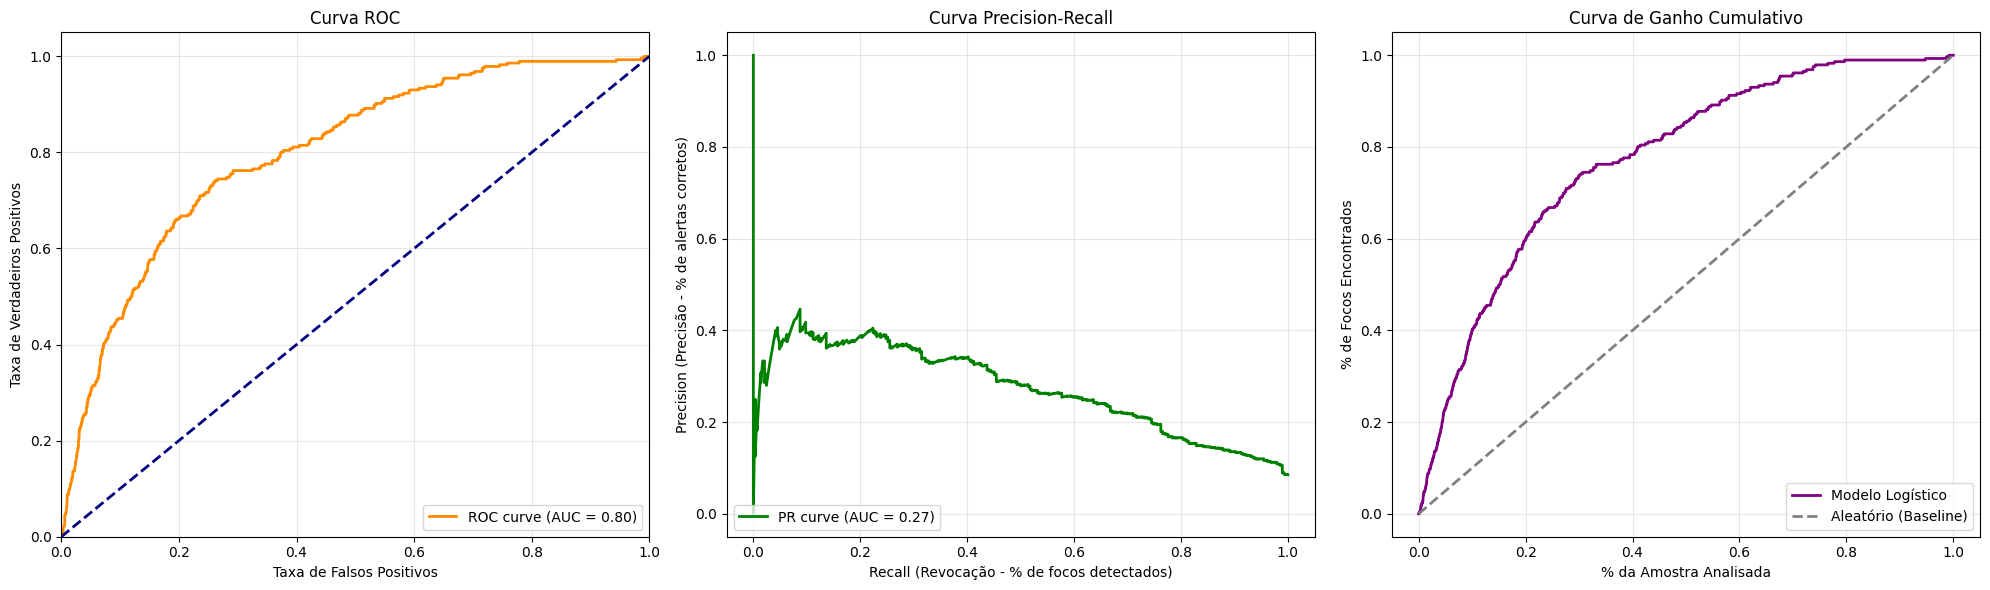

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# 1. Extração das Probabilidades Matemáticas do modelo
y_prob_classe1 = modelo.predict_proba(X)[:, 1]

# Garante que 'y' seja um array numpy para evitar problemas de indexação com o Pandas
y_array = np.array(y)

# 2. Configuração da Figura
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# --- GRÁFICO 1: CURVA ROC ---
fpr, tpr, thresholds_roc = roc_curve(y_array, y_prob_classe1)
roc_auc = auc(fpr, tpr)

axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('Taxa de Falsos Positivos')
axes[0].set_ylabel('Taxa de Verdadeiros Positivos')
axes[0].set_title('Curva ROC')
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# --- GRÁFICO 2: CURVA PRECISION-RECALL ---
precision, recall, thresholds_pr = precision_recall_curve(y_array, y_prob_classe1)
pr_auc = average_precision_score(y_array, y_prob_classe1)

axes[1].plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
axes[1].set_xlabel('Recall (Revocação - % de focos detectados)')
axes[1].set_ylabel('Precision (Precisão - % de alertas corretos)')
axes[1].set_title('Curva Precision-Recall')
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

# --- GRÁFICO 3: CURVA DE GANHO (CUMULATIVE GAINS) NATIVA ---
# Ordena as predições da maior probabilidade para a menor
sorted_indices = np.argsort(y_prob_classe1)[::-1]
y_true_sorted = y_array[sorted_indices]

# Calcula as porcentagens acumuladas
cum_true = np.cumsum(y_true_sorted)
gain = cum_true / np.sum(y_array)
percentages = np.arange(1, len(y_array) + 1) / len(y_array)

# Adiciona o ponto de origem (0,0) no gráfico
percentages = np.insert(percentages, 0, 0)
gain = np.insert(gain, 0, 0)

axes[2].plot(percentages, gain, color='purple', lw=2, label='Modelo Logístico')
axes[2].plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Aleatório (Baseline)')
axes[2].set_title('Curva de Ganho Cumulativo')
axes[2].set_xlabel('% da Amostra Analisada')
axes[2].set_ylabel('% de Focos Encontrados')
axes[2].legend(loc="lower right")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

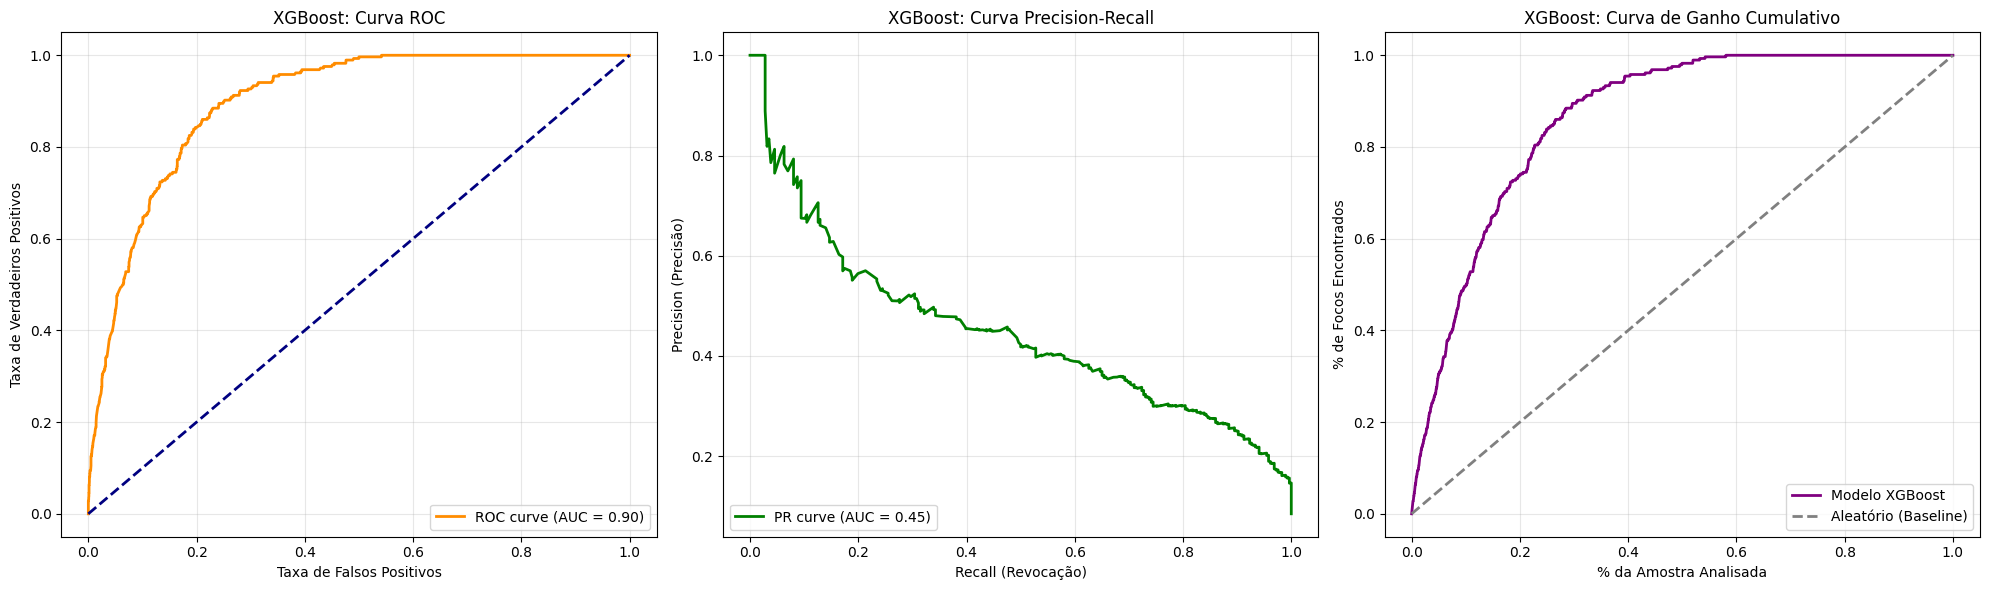

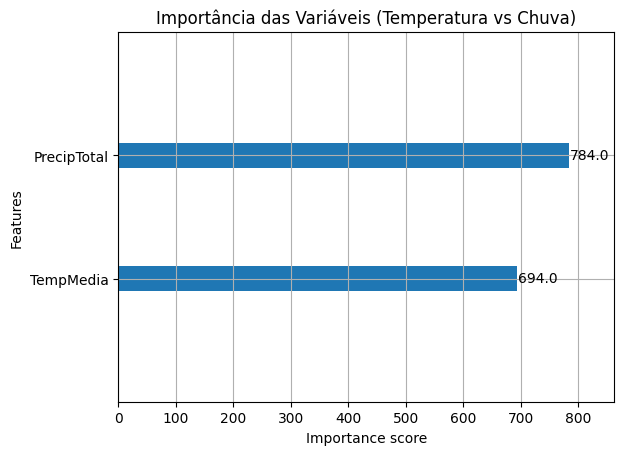

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# 1. Ajuste do Desbalanceamento
# Calcula a proporção exata entre os meses sem fogo (0) e com fogo (1) na sua base
contagem_zeros = (y == 0).sum()
contagem_uns = (y == 1).sum()
peso_classes = contagem_zeros / contagem_uns

# 2. Configuração e Treinamento do XGBoost
modelo_xgb = xgb.XGBClassifier(
    scale_pos_weight=peso_classes, # Força o modelo a dar mais atenção à minoria (incêndios)
    max_depth=4,                   # Limita a profundidade da árvore para evitar overfitting
    learning_rate=0.05,            # Taxa de aprendizado mais conservadora
    n_estimators=150,              # Quantidade de árvores de decisão geradas
    random_state=42,
    eval_metric='aucpr'            # Otimiza o modelo focado na curva Precision-Recall
)

modelo_xgb.fit(X, y)

# 3. Extração das Probabilidades do novo modelo
y_prob_xgb = modelo_xgb.predict_proba(X)[:, 1]
y_array = np.array(y)

# 4. Renderização das Curvas de Avaliação
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# --- GRÁFICO 1: CURVA ROC ---
fpr, tpr, _ = roc_curve(y_array, y_prob_xgb)
roc_auc = auc(fpr, tpr)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_title('XGBoost: Curva ROC')
axes[0].set_xlabel('Taxa de Falsos Positivos')
axes[0].set_ylabel('Taxa de Verdadeiros Positivos')
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# --- GRÁFICO 2: CURVA PRECISION-RECALL ---
precision, recall, _ = precision_recall_curve(y_array, y_prob_xgb)
pr_auc = average_precision_score(y_array, y_prob_xgb)
axes[1].plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
axes[1].set_title('XGBoost: Curva Precision-Recall')
axes[1].set_xlabel('Recall (Revocação)')
axes[1].set_ylabel('Precision (Precisão)')
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

# --- GRÁFICO 3: CURVA DE GANHO CUMULATIVO ---
sorted_indices = np.argsort(y_prob_xgb)[::-1]
y_true_sorted = y_array[sorted_indices]
cum_true = np.cumsum(y_true_sorted)
gain = cum_true / np.sum(y_array)
percentages = np.arange(1, len(y_array) + 1) / len(y_array)
percentages = np.insert(percentages, 0, 0)
gain = np.insert(gain, 0, 0)

axes[2].plot(percentages, gain, color='purple', lw=2, label='Modelo XGBoost')
axes[2].plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Aleatório (Baseline)')
axes[2].set_title('XGBoost: Curva de Ganho Cumulativo')
axes[2].set_xlabel('% da Amostra Analisada')
axes[2].set_ylabel('% de Focos Encontrados')
axes[2].legend(loc="lower right")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Exibe a importância de cada variável na decisão do algoritmo
xgb.plot_importance(modelo_xgb, importance_type='weight', title='Importância das Variáveis (Temperatura vs Chuva)')
plt.show()

In [ ]:
import joblib
from google.colab import files

# Define o nome do arquivo de saída
nome_arquivo = 'modelo_risco_incendio_xgb.pkl'

# Salva o modelo treinado (a variável do seu XGBoost) no disco do Colab
joblib.dump(modelo_xgb, nome_arquivo)

# Dispara o download automático do arquivo .pkl para o seu computador
files.download(nome_arquivo)

print(f"Modelo {nome_arquivo} exportado com sucesso!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Modelo modelo_risco_incendio_xgb.pkl exportado com sucesso!


In [ ]:
# Test UI

# %%writefile app.py
# import streamlit as st
# import pandas as pd
# import joblib
# import requests
# from geopy.geocoders import Nominatim

# st.set_page_config(page_title="Monitor de Focos", page_icon="🔥", layout="centered")

# st.title("🔥 Monitor Preditivo de Queimadas")
# st.markdown("Digite o nome de uma cidade. O sistema buscará a previsão do tempo atual na API YR e calculará o risco de incêndios severos.")

# # --- 1. Carregamento do Modelo ---
# @st.cache_resource
# def carregar_modelo():
#     return joblib.load('modelo_risco_incendio_xgb.pkl')

# try:
#     modelo = carregar_modelo()
# except Exception:
#     st.error("Erro: Arquivo 'modelo_risco_incendio_xgb.pkl' não encontrado.")
#     st.stop()

# # --- 2. Interface de Busca ---
# cidade_input = st.text_input("Nome da Cidade e Estado (Ex: Chapecó, SC):", "Brasília, DF")

# if st.button("Analisar Risco da Região", type="primary", use_container_width=True):
#     with st.spinner("Buscando coordenadas e previsão meteorológica..."):

#         # --- 3. Geocodificação (Nome -> Coordenadas) ---
#         geolocator = Nominatim(user_agent="fire_risk_app_br")
#         location = geolocator.geocode(cidade_input)

#         if not location:
#             st.error("Cidade não encontrada. Tente incluir o estado.")
#             st.stop()

#         lat, lon = location.latitude, location.longitude
#         st.success(f"📍 Região localizada: {location.address}")

#         # --- 4. Requisição na API YR ---
#         # A YR exige um User-Agent customizado, senão bloqueia a requisição
#         headers = {'User-Agent': 'MonitorQueimadasApp/1.0'}
#         url_yr = f"https://api.met.no/weatherapi/locationforecast/2.0/compact?lat={lat}&lon={lon}"

#         resposta = requests.get(url_yr, headers=headers)

#         if resposta.status_code != 200:
#             st.error("A API de clima está indisponível no momento.")
#             st.stop()

#         dados_clima = resposta.json()

#         # Extrai a temperatura atual e a precipitação prevista para as próximas 6 horas
#         tempos = dados_clima['properties']['timeseries'][0]
#         temp_atual = tempos['data']['instant']['details']['air_temperature']
#         precip_6h = tempos['data'].get('next_6_hours', {}).get('details', {}).get('precipitation_amount', 0.0)

#         # --- 5. Projeção de Escala (De 6h para Mensal) ---
#         # Como o modelo aprendeu com totais mensais, projetamos a chuva das próximas 6h para um cenário de 30 dias
#         precip_mensal_projetada = precip_6h * 4 * 30

#         st.info(f"🌡️ **Temperatura Atual:** {temp_atual}°C | 🌧️ **Projeção de Chuva Mensalizada:** {precip_mensal_projetada:.1f} mm")

#         # --- 6. Inferência do Modelo ---
#         entrada_ia = pd.DataFrame({'TempMedia': [temp_atual], 'PrecipTotal': [precip_mensal_projetada]})
#         probabilidade = modelo.predict_proba(entrada_ia)[0][1]

#         # --- 7. Resposta Visual ---
#         st.divider()
#         st.subheader("Diagnóstico da Inteligência Artificial")

#         if probabilidade >= 0.7:
#             st.error(f"🚨 **Risco Crítico:** {probabilidade:.1%} de chance de volume severo de focos.")
#         elif probabilidade >= 0.4:
#             st.warning(f"⚠️ **Risco Moderado:** {probabilidade:.1%} de chance de aumento de focos.")
#         else:
#             st.success(f"✅ **Risco Baixo:** {probabilidade:.1%} de chance. Clima desfavorável ao fogo.")

#         st.progress(float(probabilidade))

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import requests
import folium
from streamlit_folium import st_folium
from geopy.geocoders import Nominatim

st.set_page_config(page_title="Monitor de Focos", page_icon="🔥", layout="wide")

# --- Inicialização do Estado (Memória da Aplicação) ---
if "pontos_analisados" not in st.session_state:
    st.session_state.pontos_analisados = []
if "ultimo_clique" not in st.session_state:
    st.session_state.ultimo_clique = None

st.title("🔥 Monitor Preditivo de Queimadas no Brasil")
st.markdown("Clique em qualquer ponto do mapa para analisar o risco de incêndio. **O modelo atua estritamente em território brasileiro.**")

# --- Função de Gradiente de Cor (Verde -> Amarelo -> Vermelho) ---
def obter_cor_gradiente(prob):
    p = max(0.0, min(1.0, prob))
    if p < 0.5:
        # De Verde (#2ecc71) para Amarelo (#f1c40f)
        f = p * 2.0
        r = int(46 + (241 - 46) * f)
        g = int(204 + (196 - 204) * f)
        b = int(113 + (15 - 113) * f)
    else:
        # De Amarelo (#f1c40f) para Vermelho (#e74c3c)
        f = (p - 0.5) * 2.0
        r = int(241 + (231 - 241) * f)
        g = int(196 + (76 - 196) * f)
        b = int(15 + (60 - 15) * f)
    return f"#{r:02x}{g:02x}{b:02x}"

# --- 1. Carregamento do Modelo ---
@st.cache_resource
def carregar_modelo():
    try:
        return joblib.load('modelo_risco_incendio_xgb.pkl')
    except Exception:
        # Mock para testes caso não tenha o modelo
        class MockModel:
            def predict_proba(self, df):
                return [[0, min(df['TempMedia'].iloc[0] / 40.0, 0.99)]]
        return MockModel()

modelo = carregar_modelo()

# --- Layout em duas colunas ---
col_mapa, col_info = st.columns([2, 1])

with col_mapa:
    # --- 2. Configuração do Mapa com Limites do Brasil ---
    m = folium.Map(
        location=[-14.2350, -51.9253],
        zoom_start=4,
        min_zoom=4, # Impede o usuário de dar zoom out no mundo inteiro
        max_bounds=True, # Trava a área de arrasto
        min_lat=-35.0, max_lat=6.0,    # Limites Norte-Sul do BR
        min_lon=-75.0, max_lon=-34.0   # Limites Leste-Oeste do BR
    )

    # Adiciona camada para deixar o mundo cinza exceto o Brasil
    try:
        url_world = "https://raw.githubusercontent.com/python-visualization/folium/master/examples/data/world-countries.json"
        world_geo = requests.get(url_world).json()

        folium.GeoJson(
            world_geo,
            style_function=lambda feature: {
                'fillColor': 'transparent' if feature['id'] == 'BRA' else '#cccccc',
                'color': '#888888',
                'weight': 1,
                'fillOpacity': 0.7 if feature['id'] != 'BRA' else 0.0
            }
        ).add_to(m)
    except Exception:
        pass # Fallback caso falhe o download do GeoJSON

    # Desenha todos os pontos que já estão na memória com cor em gradiente
    for ponto in st.session_state.pontos_analisados:
        cor_hex = obter_cor_gradiente(ponto['risco'])
        folium.CircleMarker(
            location=[ponto['lat'], ponto['lon']],
            radius=8,
            color=cor_hex,
            fill=True,
            fill_color=cor_hex,
            fill_opacity=0.8,
            tooltip=f"{ponto['cidade']} - Risco: {ponto['risco']:.1%}"
        ).add_to(m)

    # Renderiza o mapa e escuta eventos de clique
    mapa_interativo = st_folium(m, height=600, width=700, returned_objects=["last_clicked"])

with col_info:
    st.subheader("Análise da Região")

    # --- 3. Lógica de Clique e Processamento ---
    if mapa_interativo.get("last_clicked"):
        lat = mapa_interativo["last_clicked"]["lat"]
        lon = mapa_interativo["last_clicked"]["lng"]
        coordenada_atual = (lat, lon)

        if coordenada_atual != st.session_state.ultimo_clique:
            st.session_state.ultimo_clique = coordenada_atual

            with st.spinner("Verificando jurisdição territorial..."):
                geolocator = Nominatim(user_agent="fire_risk_app_br")
                try:
                    location = geolocator.reverse((lat, lon), language='pt')

                    if location:
                        endereco = location.raw.get('address', {})
                        pais = endereco.get('country_code', '')

                        # VERIFICAÇÃO DE TERRITÓRIO
                        if pais != 'br':
                            st.error("⚠️ **Fora de Limites!** O ponto clicado pertence a outro país (ou oceano). Este modelo foi treinado exclusivamente para o Brasil.")
                        else:
                            # Extração de nome amigável para o local
                            nome_cidade = endereco.get('city', endereco.get('town', endereco.get('village', endereco.get('municipality', 'Área Remota'))))
                            estado = endereco.get('state', '')
                            local_nome = f"{nome_cidade}, {estado}" if estado else nome_cidade

                            # Requisição na API YR
                            headers = {'User-Agent': 'MonitorQueimadasApp/1.0'}
                            url_yr = f"https://api.met.no/weatherapi/locationforecast/2.0/compact?lat={lat}&lon={lon}"
                            resposta = requests.get(url_yr, headers=headers)

                            if resposta.status_code == 200:
                                dados_clima = resposta.json()
                                tempos = dados_clima['properties']['timeseries'][0]
                                temp_atual = tempos['data']['instant']['details']['air_temperature']
                                precip_6h = tempos['data'].get('next_6_hours', {}).get('details', {}).get('precipitation_amount', 0.0)

                                precip_mensal_projetada = precip_6h * 30

                                # Inferência do Modelo
                                entrada_ia = pd.DataFrame({'TempMedia': [temp_atual], 'PrecipTotal': [precip_mensal_projetada]})
                                probabilidade = modelo.predict_proba(entrada_ia)[0][1]

                                # Salva no estado
                                st.session_state.pontos_analisados.append({
                                    'lat': lat,
                                    'lon': lon,
                                    'cidade': local_nome,
                                    'risco': probabilidade,
                                    'temp': temp_atual,
                                    'precip': precip_mensal_projetada
                                })

                                st.rerun()
                            else:
                                st.error("Erro ao buscar dados climáticos para esta coordenada.")
                    else:
                        st.error("Coordenada não reconhecida.")
                except Exception as e:
                    st.error("Falha ao comunicar com o serviço de geolocalização.")

    # --- 4. Exibição do último resultado processado ---
    if st.session_state.pontos_analisados:
        ultimo_ponto = st.session_state.pontos_analisados[-1]
        st.write(f"📍 **Local:** {ultimo_ponto['cidade']}")
        st.info(f"🌡️ **Temp:** {ultimo_ponto['temp']}°C | 🌧️ **Chuva (proj):** {ultimo_ponto['precip']:.1f} mm")

        prob = ultimo_ponto['risco']
        if prob >= 0.7:
            st.error(f"🚨 **Risco Crítico:** {prob:.1%}")
        elif prob >= 0.4:
            st.warning(f"⚠ **Risco Moderado:** {prob:.1%}")
        else:
            st.success(f"✅ **Risco Baixo:** {prob:.1%}")
        st.progress(float(prob))
    elif not mapa_interativo.get("last_clicked"):
         st.write("👆 Clique no mapa para iniciar a análise.")

Overwriting app.py


In [ ]:
import urllib.request
ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip("\n")
print(f"Sua senha de acesso para o túnel é: {ip}")

Sua senha de acesso para o túnel é: 35.252.104.35


In [ ]:
# LocalTunnel (Don't Update Dynamicaly -> Replaced By CloudFlare Tunnel)
# !wget -q -O - ipv4.icanhazip.com
# !streamlit run app.py &>/content/logs.txt &
# !npx localtunnel --port 8501

In [ ]:
!pkill -f streamlit
!pkill -f cloudflared

from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

Mudar para a biblioteca "pyngrok" caso cloudflare continue dando problema.

In [ ]:
!nohup streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &
!cloudflared tunnel --url http://localhost:8501 --protocol http2

2026-11-02T22:06:20Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-02T22:06:20Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-02T22:06:24Z INF +--------------------------------------------------------------------------------------------+
2026-11-02T22:06:24Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-02T22:06:24Z INF |  https://bumper-through-considered-guards.trycloudflar